In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

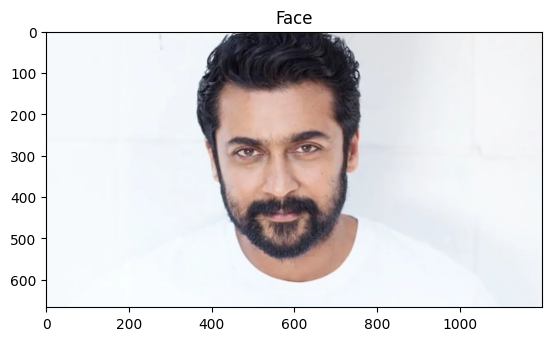

In [5]:

faceImage = cv2.imread('actor_photo.jpg')
plt.imshow(faceImage[:, :, ::-1])
plt.title("Face")



In [6]:
faceImage.shape

(667, 1200, 3)

In [7]:

faceImage.shape

(667, 1200, 3)

Text(0.5, 1.0, 'glassPNG')

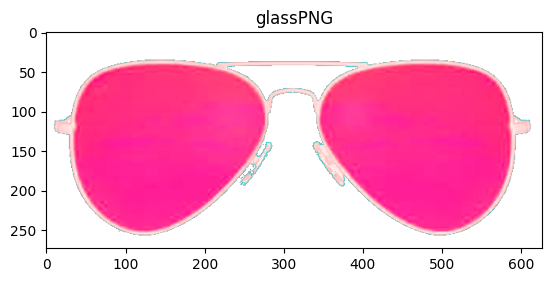

In [8]:

# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [13]:

glassPNG = cv2.resize(glassPNG,(260,65))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(65, 260, 4)


In [14]:

glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

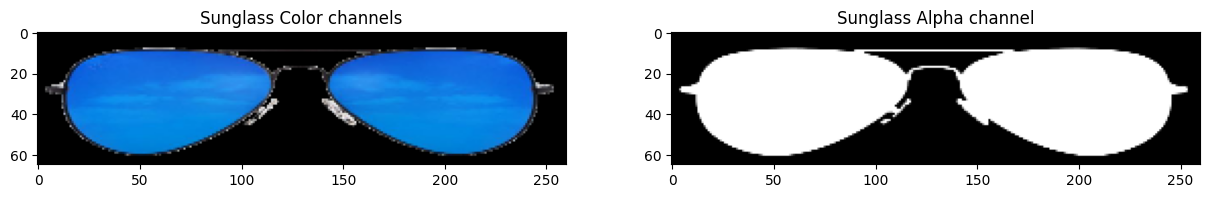

In [15]:

plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

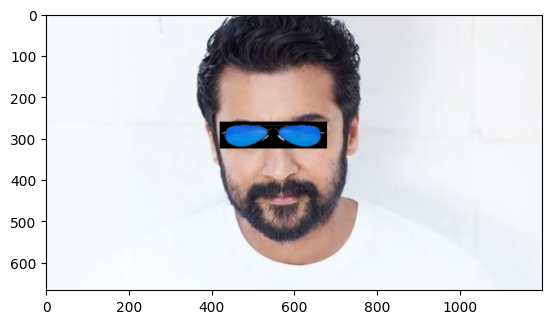

In [16]:
faceWithGlassesNaive = faceImage.copy()
faceWithGlassesNaive[260:325, 420:680]=glassBGR
plt.imshow(faceWithGlassesNaive[...,::-1])

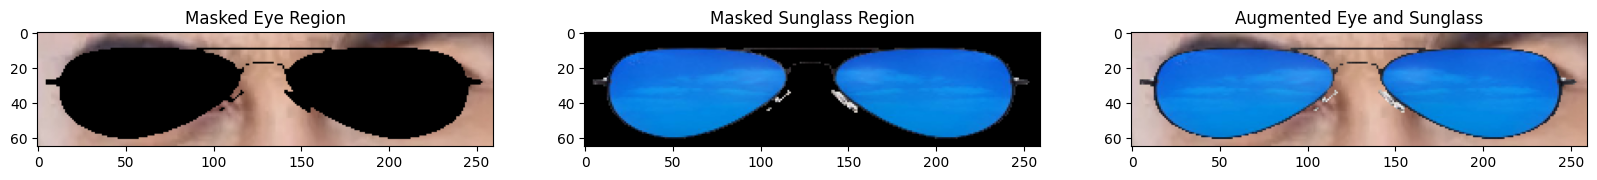

In [18]:

glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

glassMask = np.uint8(glassMask / 255)

faceWithGlassesArithmetic = faceImage.copy()

eyeROI = faceWithGlassesArithmetic[255:320, 420:680]

maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

maskedGlass = cv2.multiply(glassBGR, glassMask)

eyeROI_final = cv2.add(maskedEye, maskedGlass)

plt.figure(figsize=[20, 20])

plt.subplot(131)
plt.imshow(maskedEye[..., ::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[..., ::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeROI_final[..., ::-1])
plt.title("Augmented Eye and Sunglass")

plt.show()

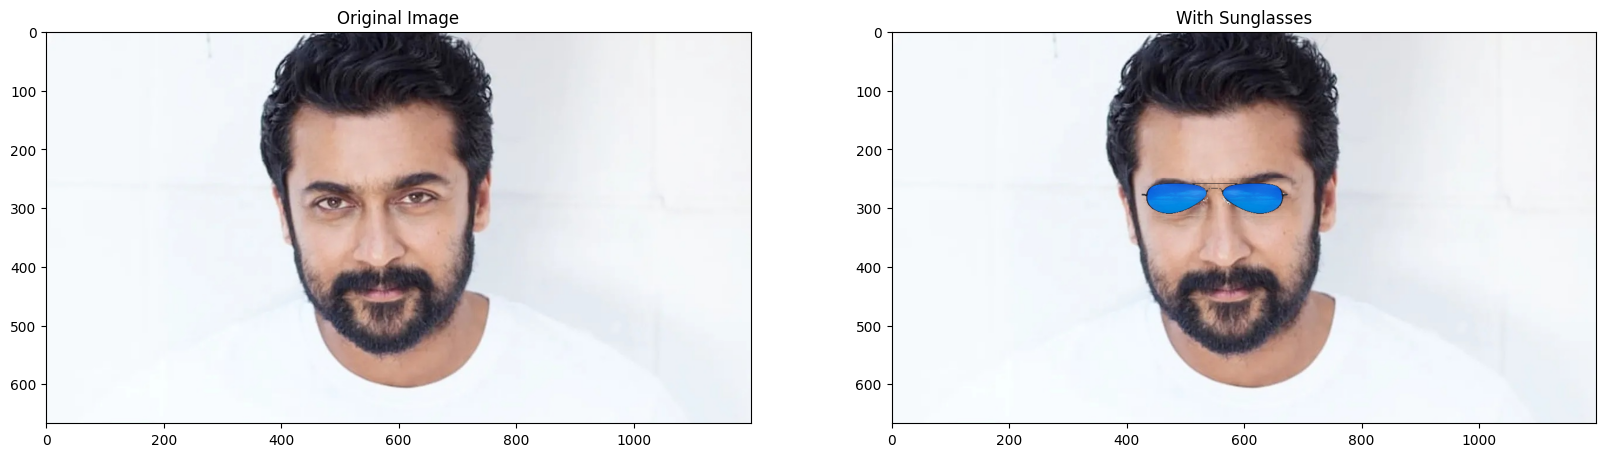

In [19]:
faceWithGlassesArithmetic[250:315, 420:680] = eyeROI_final
plt.figure(figsize=(20, 20))
plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")
plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")
plt.show()